<a href="https://colab.research.google.com/github/RaniaChaudhry511/CODE-ALPHA-INTERNSHIP/blob/main/DISEASE_PREDICTION_TASK_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diabetes Prediction using Random Forest
**CodeAlpha Machine Learning Internship | Task 4: Disease Prediction from Medical Data**

## Objective
To predict whether a patient is likely to have diabetes based on medical measurements, using a Random Forest classifier.

## Dataset
Pima Indians Diabetes Dataset (UCI ML Repository)
- 768 patient records, 8 input features, 1 target column
- **Features:** Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age
- **Target:** Outcome (1 = Diabetic, 0 = Non-diabetic)

## Approach
1. Load and explore the data
2. Clean the data (handle invalid zero values)
3. Exploratory data analysis
4. Train-test split
5. Train a Random Forest model
6. Evaluate using Accuracy, Precision, Recall, F1-Score and ROC-AUC
7. Tune hyperparameters
8. Analyze feature importance

## Tools
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn



## Step 1: Import Libraries
In this step we import the libraries needed for the project:
- **NumPy and Pandas** for data handling
- **Matplotlib and Seaborn** for visualization

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Step 2: Upload the Dataset
In this step we upload the diabetes dataset (CSV file) into the Google Colab environment so that we can read and analyze it in the next steps.

In [3]:
df = pd.read_csv("/content/diabetes_dataset.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Step 3: Load and Explore the Data
In this step we load the dataset into a Pandas DataFrame and take a first look at it:
- Check the number of rows and columns
- View the first few records
- Check data types and summary statistics
- Check how many patients are diabetic and non-diabetic

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [6]:
df["Outcome"].value_counts()

,count
Outcome,
0,500
1,268


In [7]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
(df[cols] == 0).sum()

,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


### Zero Value Check
- Glucose has 5 zero values, BloodPressure 35, SkinThickness 227, Insulin 374 and BMI 11.
- A person cannot have zero glucose, blood pressure or BMI, so these zeros represent **missing data**.
- Insulin (374) and SkinThickness (227) have the most missing values.
- These will be replaced with NaN and filled with the median in the data cleaning step.

### Observations
- The dataset has **768 rows and 9 columns** (8 input features and 1 target column `Outcome`).
- All columns show **768 non-null** values, so there are no missing values in the raw data.
- All columns are numeric (`int64` or `float64`), so no encoding is needed.
- The target `Outcome` has 500 non-diabetic (0) and 268 diabetic (1) patients, so the data is **slightly imbalanced** (about 65% vs 35%).
- The summary statistics show a minimum value of **0** in Glucose, BloodPressure, SkinThickness, Insulin and BMI. These values are not possible for a living person, so they are actually missing values and will be handled in the cleaning step.

## Step 4: Data Cleaning
In this step we handle the invalid values in the dataset:
- Glucose, BloodPressure, SkinThickness, Insulin and BMI contain zeros, which are not possible medical values
- We replace these zeros with NaN (missing values)
- We check how many missing values each column has
- The missing values will be filled later, after the train-test split, to avoid data leakage

In [8]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols] = df[cols].replace(0, np.nan)
df.isnull().sum()

,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


### Observation
- The zero values in the 5 columns have been converted to NaN, so they are now counted as missing values.
- Insulin (374) and SkinThickness (227) have the most missing values, about 49% and 30% of the data.
- Pregnancies, DiabetesPedigreeFunction, Age and Outcome have no missing values.
- These missing values will be filled with the median after the train-test split.

## Step 5: Exploratory Data Analysis (EDA)
In this step we visualize the data to understand it better:
- A count plot to see the balance between diabetic and non-diabetic patients
- Histograms to see the distribution of each feature
- A correlation heatmap to see which features are related to the Outcome

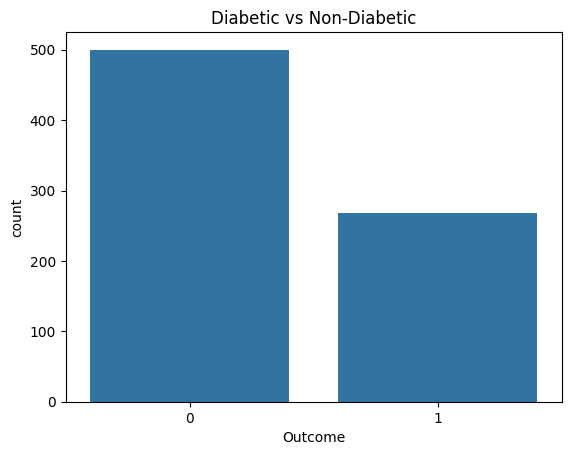

In [9]:
sns.countplot(x="Outcome", data=df)
plt.title("Diabetic vs Non-Diabetic")
plt.show()

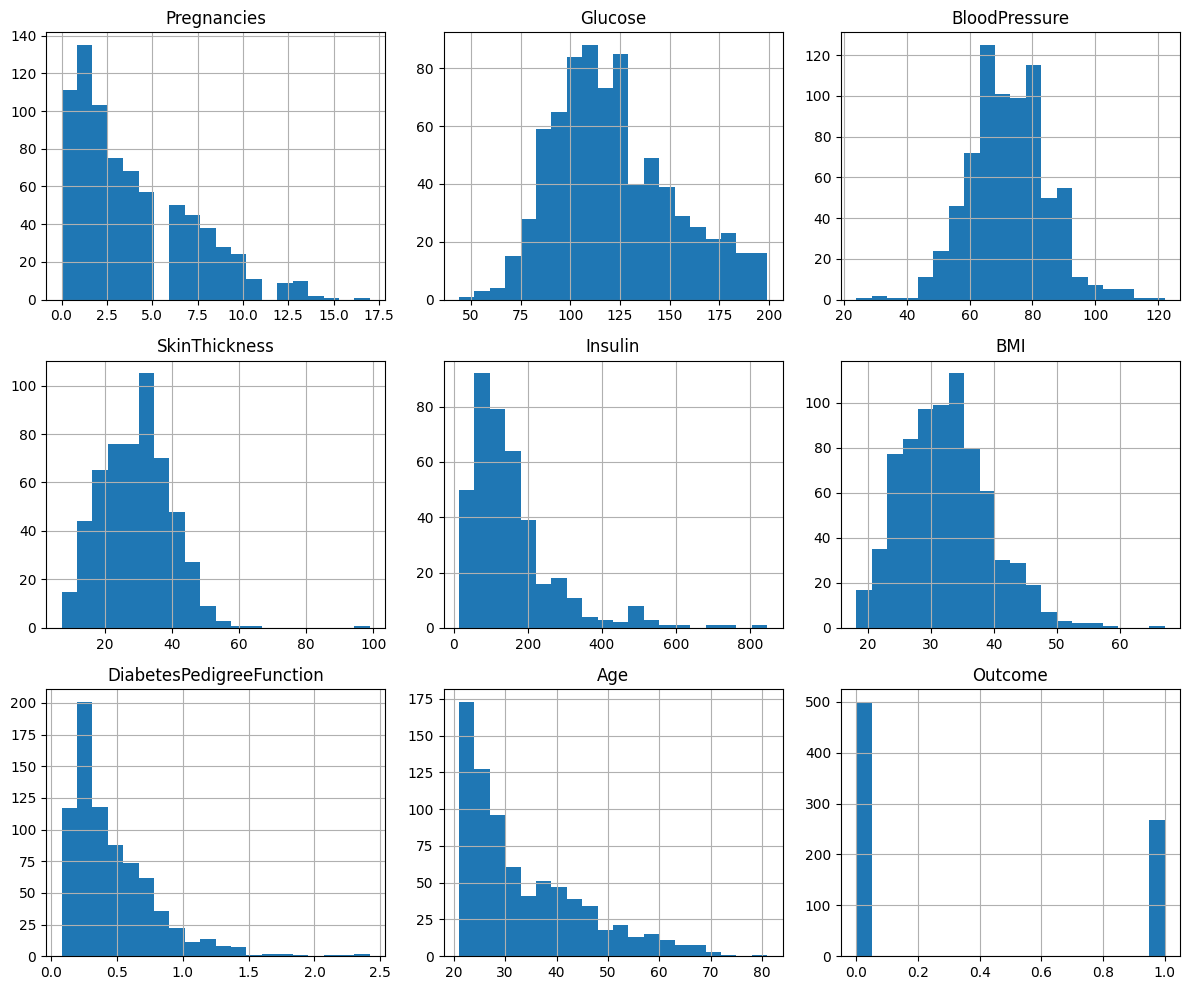

In [10]:
df.hist(figsize=(12, 10), bins=20)
plt.tight_layout()
plt.show()

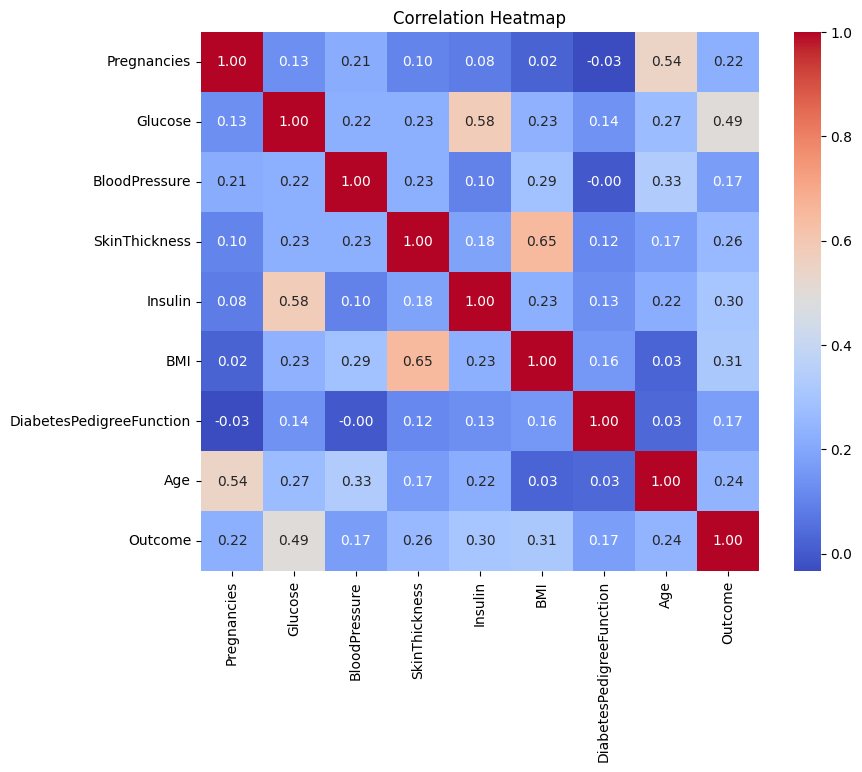

In [11]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

### Observations (EDA)

**Class balance**
- Non-diabetic (0) patients are about 500 and diabetic (1) patients are about 268, so the data is moderately imbalanced.

**Distributions**
- Glucose, BloodPressure and BMI are roughly bell-shaped (close to normal distribution).
- Pregnancies, Insulin, Age and DiabetesPedigreeFunction are right-skewed, meaning most patients have low values and a few have very high values.
- Insulin has a long tail up to about 800, which indicates outliers.

**Correlation with Outcome**
- Glucose has the strongest correlation with Outcome (0.49), so it is the most important predictor.
- BMI (0.31), Insulin (0.30), SkinThickness (0.26), Age (0.24) and Pregnancies (0.22) have a moderate positive correlation.
- BloodPressure and DiabetesPedigreeFunction have the weakest correlation (0.17).

**Correlation between features**
- SkinThickness and BMI (0.65), Glucose and Insulin (0.58), and Age and Pregnancies (0.54) are moderately correlated.
- No pair of features is extremely correlated (above 0.8), so there is no serious multicollinearity problem.

## Step 6: Train-Test Split
In this step we prepare the data for modeling:
- Separate the input features (X) from the target column (Outcome = y)
- Split the data into 80% training and 20% testing sets
- Use `stratify=y` so both sets keep the same ratio of diabetic and non-diabetic patients
- Use `random_state=42` so the results are reproducible

In [12]:
from sklearn.model_selection import train_test_split

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (614, 8)
Test shape: (154, 8)


### Observation
- The data is split into 614 training samples (80%) and 154 testing samples (20%).
- Both sets have 8 input features.
- Stratified splitting keeps the diabetic/non-diabetic ratio the same in both sets.

## Step 7: Handle Missing Values
In this step we fill the missing (NaN) values:
- We calculate the median of each column from the **training set only**
- We use these medians to fill missing values in both the training and testing sets
- Doing this after the split prevents data leakage, because the test data does not influence the training process

In [13]:
medians = X_train.median()

X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

0
0


### Observation
- All missing values have been filled with the median of the training set.
- Both training and testing sets now have 0 missing values and are ready for model training.

## Step 8: Train the Random Forest Model
In this step we build and train the baseline model:
- Random Forest combines many decision trees and takes a majority vote, which makes predictions more stable
- `n_estimators=200` means the forest has 200 trees
- `class_weight="balanced"` gives more importance to the minority class (diabetic patients) because the data is imbalanced
- The model learns from the training set only

In [14]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)

## Step 9: Evaluate the Model
In this step we test the trained model on the unseen test set:
- Predict the class (diabetic or not) and the probability for each test patient
- Calculate Accuracy, Precision, Recall, F1-Score and ROC-AUC
- Print a classification report
- Plot a confusion matrix to see correct and wrong predictions

In [15]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))
print()
print(classification_report(y_test, y_pred, target_names=["Non-Diabetic", "Diabetic"]))

Accuracy : 0.7402597402597403
Precision: 0.6521739130434783
Recall   : 0.5555555555555556
F1-Score : 0.6
ROC-AUC  : 0.8123148148148147

              precision    recall  f1-score   support

Non-Diabetic       0.78      0.84      0.81       100
    Diabetic       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154



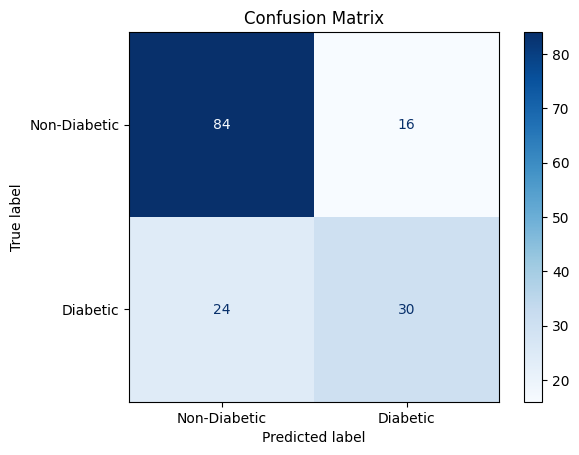

In [16]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Non-Diabetic", "Diabetic"]).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

### Observations (Baseline Model)

**Overall performance**
- Accuracy is 74.0%, meaning the model predicts correctly for about 114 out of 154 test patients.
- ROC-AUC is 0.81, which shows the model separates diabetic and non-diabetic patients reasonably well.

**Confusion matrix**
- 84 non-diabetic patients were correctly predicted (True Negatives) and 30 diabetic patients were correctly predicted (True Positives).
- 16 non-diabetic patients were wrongly predicted as diabetic (False Positives).
- 24 diabetic patients were wrongly predicted as non-diabetic (False Negatives).

**Class-wise performance**
- For the Non-Diabetic class, precision is 0.78 and recall is 0.84, so the model performs well here.
- For the Diabetic class, precision is 0.65 and recall is 0.56, so the model is weaker here.
- The model misses 24 of 54 diabetic patients (recall 56%). In medical problems, missing a diabetic patient is more serious than a false alarm, so recall for the diabetic class should be improved.

**Next step**
- We will tune the hyperparameters with GridSearchCV to improve the results.

## Step 10: ROC Curve
In this step we plot the ROC (Receiver Operating Characteristic) curve:
- It shows the trade-off between the True Positive Rate and the False Positive Rate at different thresholds
- The dashed diagonal line represents a random guess
- The closer the curve is to the top-left corner, the better the model
- AUC (Area Under the Curve) summarizes the performance in a single number

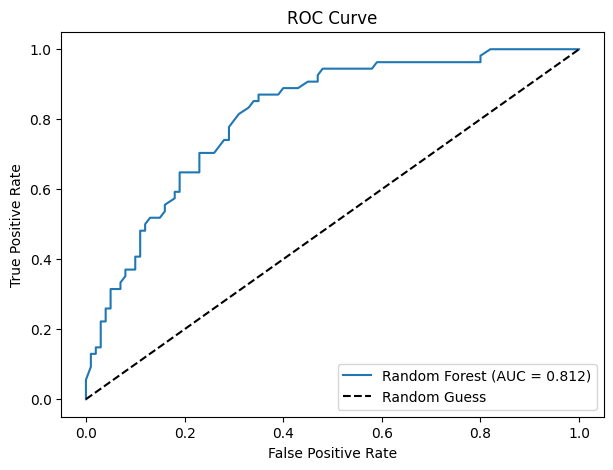

In [17]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_prob):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

### Observation
- The ROC curve stays well above the diagonal random-guess line, so the model performs clearly better than chance.
- The AUC is 0.812, which indicates good ability to separate diabetic and non-diabetic patients.

## Step 11: Hyperparameter Tuning
In this step we try to improve the model by finding the best Random Forest settings:
- GridSearchCV tests many combinations of hyperparameters
- 5-fold cross-validation is used on the training set to evaluate each combination
- ROC-AUC is used as the scoring metric
- The best combination is selected automatically
- Parameters tuned: `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`

In [18]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 8, 12],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42, class_weight="balanced"),
    param_grid, cv=5, scoring="roc_auc", n_jobs=-1)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV ROC-AUC:", grid.best_score_)

best = grid.best_estimator_

Best parameters: {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 300}
Best CV ROC-AUC: 0.8380301771871539


### Observation
- GridSearchCV selected: `max_depth=5`, `min_samples_leaf=4`, `min_samples_split=2`, `n_estimators=300`.
- The best cross-validation ROC-AUC is 0.838.
- The best model uses shallow trees (max_depth=5) with larger leaves, which reduces overfitting.

## Step 12: Evaluate the Tuned Model
In this step we test the best model from GridSearchCV on the test set:
- Calculate the same metrics as before (Accuracy, Precision, Recall, F1-Score, ROC-AUC)
- Plot the confusion matrix
- Compare the results with the baseline model

In [19]:
y_pred_best = best.predict(X_test)
y_prob_best = best.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best))
print("Recall   :", recall_score(y_test, y_pred_best))
print("F1-Score :", f1_score(y_test, y_pred_best))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_best))
print()
print(classification_report(y_test, y_pred_best, target_names=["Non-Diabetic", "Diabetic"]))

Accuracy : 0.7272727272727273
Precision: 0.5882352941176471
Recall   : 0.7407407407407407
F1-Score : 0.6557377049180327
ROC-AUC  : 0.8207407407407408

              precision    recall  f1-score   support

Non-Diabetic       0.84      0.72      0.77       100
    Diabetic       0.59      0.74      0.66        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.71       154
weighted avg       0.75      0.73      0.73       154



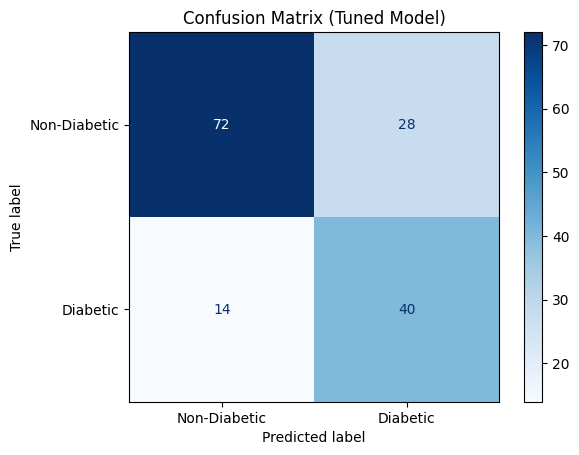

In [20]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_best),
                       display_labels=["Non-Diabetic", "Diabetic"]).plot(cmap="Blues")
plt.title("Confusion Matrix (Tuned Model)")
plt.show()

In [21]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Baseline": [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
                 recall_score(y_test, y_pred), f1_score(y_test, y_pred),
                 roc_auc_score(y_test, y_prob)],
    "Tuned": [accuracy_score(y_test, y_pred_best), precision_score(y_test, y_pred_best),
              recall_score(y_test, y_pred_best), f1_score(y_test, y_pred_best),
              roc_auc_score(y_test, y_prob_best)]
}).round(3)
comparison

,Metric,Baseline,Tuned
0,Accuracy,0.740,0.727
1,Precision,0.652,0.588
2,Recall,0.556,0.741
3,F1-Score,0.600,0.656
4,ROC-AUC,0.812,0.821


### Observations (Tuned Model vs Baseline)

**Confusion matrix (tuned model)**
- 72 non-diabetic patients were correctly predicted and 40 diabetic patients were correctly predicted.
- 28 non-diabetic patients were wrongly predicted as diabetic (False Positives).
- Only 14 diabetic patients were missed (False Negatives), compared to 24 in the baseline model.

**Comparison**
- Recall for the diabetic class improved from 0.556 to 0.741, so the model now detects about 74% of diabetic patients instead of 56%.
- F1-Score improved from 0.600 to 0.656 and ROC-AUC improved slightly from 0.812 to 0.821.
- Accuracy dropped slightly from 0.740 to 0.727 and Precision dropped from 0.652 to 0.588, because the model now predicts "diabetic" more often, which creates more false alarms.

**Conclusion**
- In a medical screening problem, missing a diabetic patient is more harmful than a false alarm, so the tuned model is the better choice despite the small drop in accuracy.

## Step 13: Feature Importance
In this step we check which features the tuned Random Forest model considers most important for predicting diabetes. Random Forest calculates this from how much each feature helps to reduce impurity across all its trees.

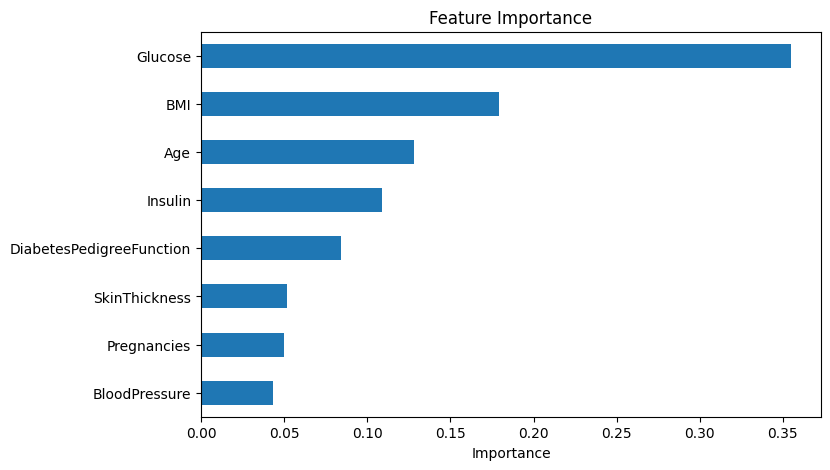

,0
Glucose,0.355
BMI,0.179
Age,0.128
Insulin,0.109
DiabetesPedigreeFunction,0.084
SkinThickness,0.052
Pregnancies,0.050
BloodPressure,0.044


In [22]:
importance = pd.Series(best.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind="barh")
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.show()

importance.sort_values(ascending=False).round(3)

### Observations (Feature Importance)
- **Glucose** is by far the most important feature (0.355), more than double the next one. This matches the correlation heatmap, where Glucose had the highest correlation with Outcome.
- **BMI** (0.179) and **Age** (0.128) are the second and third most important features.
- **Insulin** (0.109) and **DiabetesPedigreeFunction** (0.084) have a moderate importance.
- **SkinThickness** (0.052), **Pregnancies** (0.050) and **BloodPressure** (0.044) contribute the least.
- Overall, blood glucose level, body weight and age are the main factors the model uses to predict diabetes.

## Step 14: Save the Model and Predict for a New Patient
In this step we:
- Save the trained model and the training medians to a file using `joblib`, so it can be reused without retraining
- Predict the diabetes outcome for a new patient using the saved model

In [23]:
import joblib

joblib.dump({"model": best, "medians": medians}, "diabetes_rf_model.pkl")
print("Model saved")

Model saved


In [24]:
saved = joblib.load("diabetes_rf_model.pkl")
model = saved["model"]

new_patient = pd.DataFrame(
    [[2, 140, 80, 30, 120, 32.0, 0.5, 40]],
    columns=X.columns)

prediction = model.predict(new_patient)[0]
probability = model.predict_proba(new_patient)[0][1]

print("Prediction:", "Diabetic" if prediction == 1 else "Non-Diabetic")
print(f"Probability of diabetes: {probability:.2%}")

Prediction: Diabetic
Probability of diabetes: 64.97%


### Observation
- The model was saved successfully as `diabetes_rf_model.pkl` and loaded again without retraining.
- For the sample patient (Glucose 140, BMI 32, Age 40), the model predicts **Diabetic** with a probability of about 65%.

## Conclusion
In this project we built a Random Forest model to predict diabetes using the Pima Indians Diabetes dataset.

**What we did**
- Explored the data and found that zero values in Glucose, BloodPressure, SkinThickness, Insulin and BMI were actually missing values.
- Replaced them with the median of the training set after the train-test split to avoid data leakage.
- Trained a baseline Random Forest and then tuned it with GridSearchCV.

**Results**

| Metric | Baseline | Tuned |
|---|---|---|
| Accuracy | 0.740 | 0.727 |
| Precision | 0.652 | 0.588 |
| Recall | 0.556 | 0.741 |
| F1-Score | 0.600 | 0.656 |
| ROC-AUC | 0.812 | 0.821 |

**Key findings**
- The tuned model detects about 74% of diabetic patients, compared to 56% for the baseline, which is important in medical screening.
- Glucose, BMI and Age are the most important features for predicting diabetes.
- The final model was saved and can be used to predict new patients.

**Limitations and future work**
- The dataset is small (768 records) and moderately imbalanced.
- Other models such as XGBoost, SVM or Logistic Regression can be compared.
- Techniques like SMOTE or threshold tuning can be tried to improve precision and recall further.
- This model is for learning purposes and is not a substitute for medical diagnosis.